<a href="https://colab.research.google.com/github/SkrybaOtis/Systemy_AI/blob/main/SystemyAI_Lab5_Cukrzyca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Systemy AI – Laboratorium 5
## Zadanie: który klasyfikator najlepiej rozpoznaje cukrzycę?

Zbiór **Pima Indians Diabetes**: 768 kobiet z plemienia Pima (Arizona, USA). Zadanie: na podstawie wyników badań przewidzieć, czy u pacjentki zdiagnozowano cukrzycę w ciągu 5 lat (`outcome` = 1).

Wykonaj całą procedurę z notatnika `SystemyAI_Lab5_Titanic_CV.ipynb`: porównaj klasyfikatory walidacją krzyżową, dostrój hiperparametry, wybierz najlepszy model i **dopiero na końcu, raz**, oceń go na zbiorze testowym. Cały kod piszesz sam(a).

| Kolumna | Znaczenie |
|---|---|
| `pregnancies` | liczba ciąż |
| `glucose` | stężenie glukozy po 2 h w doustnym teście obciążenia glukozą [mg/dl] |
| `blood_pressure` | ciśnienie rozkurczowe [mm Hg] |
| `skin_thickness` | grubość fałdu skórnego na tricepsie [mm] |
| `insulin` | stężenie insuliny po 2 h [μU/ml] |
| `bmi` | wskaźnik masy ciała [kg/m²] |
| `pedigree` | wskaźnik obciążenia rodzinnego cukrzycą |
| `age` | wiek [lata] |
| `outcome` | **etykieta**: 1 = cukrzyca, 0 = brak |

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie danych
Plik nie ma wiersza nagłówka, więc nazwy kolumn trzeba podać samemu:

```python
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
```
Zaimportuj potrzebne biblioteki, wczytaj dane do `df` i obejrzyj je (`shape`, `head()`, `describe()`).

In [ ]:
# Twoje rozwiązanie
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     validation_curve, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, accuracy_score

URL = "/home/gustaw/Downloads/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)

print(df.shape)
print(df.head())
print(df.describe())

(768, 9)
   pregnancies  glucose  blood_pressure  skin_thickness  insulin   bmi  \
0            6      148              72              35        0  33.6   
1            1       85              66              29        0  26.6   
2            8      183              64               0        0  23.3   
3            1       89              66              23       94  28.1   
4            0      137              40              35      168  43.1   

   pedigree  age  outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  
       pregnancies     glucose  blood_pressure  skin_thickness     insulin  \
count   768.000000  768.000000      768.000000      768.000000  768.000000   
mean      3.845052  120.894531       69.105469       20.536458   79.799479   
std       3.369578   31.972618       19.355807       15.952218  115.244002   
min       0.000000    0.000000        0.000000        0.000000    

In [ ]:
# TEST
assert df.shape == (768, 9) and list(df.columns)[-1] == "outcome"
print("1 OK")

1 OK


---
## 2. EDA i ukryte braki
1. `class_share` – udział każdej klasy w `outcome`.
2. `df.isna().sum()` – czy są braki? Teraz policz `zeros` – liczbę **zer** w każdej kolumnie cech.
3. Narysuj `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`: po lewej histogram `glucose`, po prawej histogram `insulin`, oba z kolorem według `outcome` (`sns.histplot(..., hue="outcome")`).

outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64
pregnancies       0
glucose           0
blood_pressure    0
skin_thickness    0
insulin           0
bmi               0
pedigree          0
age               0
outcome           0
dtype: int64
pregnancies       111
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
outcome           500
dtype: int64


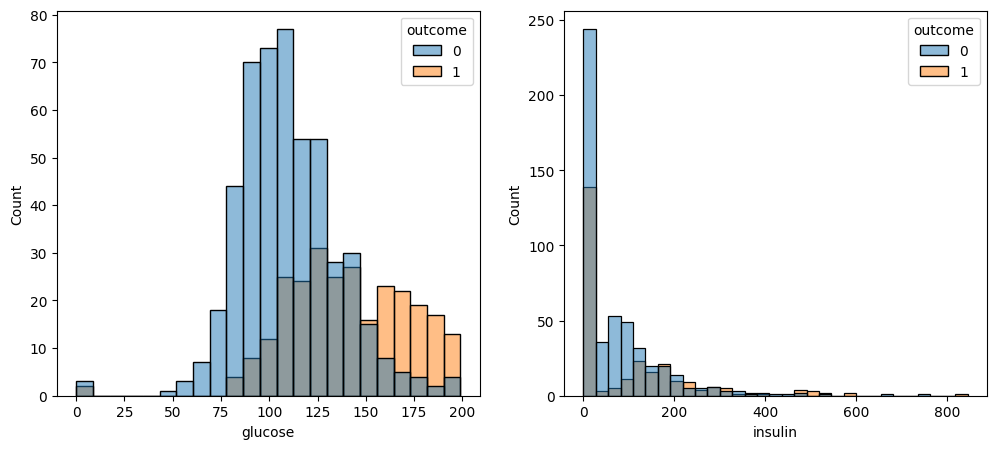

In [ ]:
# Twoje rozwiązanie
class_share = df['outcome'].value_counts(normalize=True)
print(class_share)
print(df.isna().sum())
zeros = (df[kolumny] == 0).sum()
print(zeros)


fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="glucose",  hue="outcome", ax=axes[0])
sns.histplot(data=df, x="insulin",  hue="outcome", ax=axes[1])
plt.show()

# fig, axes = plt.subplots(1, 3, figsize=(12, 5))
# sns.histplot(data=df, x="blood_pressure",  hue="outcome", ax=axes[0])
# sns.histplot(data=df, x="skin_thickness",  hue="outcome", ax=axes[1])
# sns.histplot(data=df, x="age",  hue="outcome", ax=axes[2])
# plt.show()

# fig, axes = plt.subplots(1, 3, figsize=(12, 5))
# sns.histplot(data=df, x="bmi",  hue="outcome", ax=axes[0])
# sns.histplot(data=df, x="pregnancies",  hue="outcome", ax=axes[1])
# sns.histplot(data=df, x="pedigree",  hue="outcome", ax=axes[2])
# plt.show()



In [ ]:
# TEST
assert abs(class_share[0] - 0.651) < 1e-3
assert zeros["insulin"] == 374 and zeros["glucose"] == 5 and zeros["pregnancies"] == 111
print("2 OK")

2 OK


*Twoja odpowiedź:*
1. Jaką accuracy osiągnie baseline?
- Baseline (zawsze-zero) = 0.651042 (Informacja z class_share)
2. W których kolumnach zero jest **fizycznie niemożliwe** (żyjący człowiek nie może mieć takiej wartości), a w której jest zupełnie normalne?
- Fizycznie niemożliwe:
  - glucose, blood_pressure, skin_thickness, insulin i bmi
- Zupełnie normalne:
  - pregnancies
3. Która cecha najwyraźniej różni chore i zdrowe pacjentki?
- poziom glukozy

---
## 3. Zamiana ukrytych braków na `NaN`
W kolumnach `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, `bmi` zamień zera na `np.nan` (`replace(0, np.nan)`). Wynik zapisz w `df_clean` (kopia `df`), a liczbę braków w każdej kolumnie w `missing`.

Model nie wie, że zero oznacza brak. Dla niego „insulina = 0” to po prostu bardzo niska insulina – a takich „pomiarów” jest prawie połowa.

In [ ]:
# Twoje rozwiązanie
df_clean = df.copy()
kolumny_zero = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
df_clean[kolumny_zero] = df_clean[kolumny_zero].replace(0, np.nan)
missing = df_clean.isna().sum()
print(missing)

pregnancies         0
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
outcome             0
dtype: int64


In [ ]:
# TEST
assert missing["insulin"] == 374 and missing["skin_thickness"] == 227 and missing["pregnancies"] == 0
assert (df["insulin"] == 0).sum() == 374, "Nie zmieniaj oryginalnego df - użyj copy()"
print("3 OK")

3 OK


*Twoja odpowiedź:* insuliny brakuje u prawie połowy pacjentek. Jakie masz możliwości? Co wybierasz i dlaczego?

---
## 4. Podział i przygotowanie
1. `X` – wszystkie cechy z `df_clean`, `y` – `outcome`. Podziel na `X_train, X_test, y_train, y_test` (`test_size=0.25`, `stratify=y`, `random_state=42`).
2. Napisz funkcję `model_z(klasyfikator)`, która zwraca pipeline: `SimpleImputer(strategy="median")` → `StandardScaler()` → klasyfikator. (Wszystkie cechy są liczbowe, więc `ColumnTransformer` nie jest potrzebny.)
3. Utwórz `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

In [ ]:
# Twoje rozwiązanie
# print(kolumny)
kolumny_bez_outcome = kolumny.copy()
kolumny_bez_outcome.remove("outcome")
# print(kolumny_bez_outcome)

X_train, X_test, y_train, y_test = train_test_split(df_clean[kolumny_bez_outcome], df_clean["outcome"], test_size=0.25, stratify=df_clean["outcome"], random_state=42)

def model_z(klasyfikator):
  return make_pipeline(SimpleImputer(strategy="median"),
                         StandardScaler(),
                         klasyfikator)

# print(len(model_z(None).steps))


In [ ]:
# TEST
assert X_train.shape == (576, 8) and X_test.shape == (192, 8)
assert X_train["insulin"].isna().sum() > 0, "Podział robimy na df_clean (z NaN zamiast zer)"
assert len(model_z(None).steps) == 3
print("4 OK")

4 OK


---
## 5. Porównanie klasyfikatorów walidacją krzyżową
Dla pięciu modeli z domyślnymi hiperparametrami: `DummyClassifier(strategy="most_frequent")`, `LogisticRegression()`, `KNeighborsClassifier()`, `DecisionTreeClassifier(random_state=42)`, `RandomForestClassifier(random_state=42)` policz `cross_val_score` na zbiorze treningowym i accuracy na całym zbiorze treningowym.

Zbierz wyniki w tabeli `porownanie` (indeks: `"baseline"`, `"regresja logistyczna"`, `"kNN"`, `"drzewo decyzyjne"`, `"las losowy"`; kolumny: `"CV średnia"`, `"CV odch."`, `"train"`) i narysuj wykres słupkowy średnich z odchyleniami.

In [ ]:
# Twoje rozwiązanie
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

klasyfikatory = {
    "baseline": DummyClassifier(strategy="most_frequent"),
    "regresja logistyczna": LogisticRegression(),
    "kNN": KNeighborsClassifier(),
    "drzewo decyzyjne": DecisionTreeClassifier(random_state=42),
    "las losowy": RandomForestClassifier(random_state=42),
}

wiersze = []
for nazwa, klf in klasyfikatory.items():
    model = model_z(klf)
    s = cross_val_score(model, X_train, y_train, cv=cv)
    wiersze.append({"model": nazwa, "CV średnia": s.mean(), "CV odch.": s.std(),
                    "train": model.fit(X_train, y_train).score(X_train, y_train)})
porownanie = pd.DataFrame(wiersze).set_index("model")
porownanie.round(3)

,CV średnia,CV odch.,train
model,,,
baseline,0.651,0.002,0.651
regresja logistyczna,0.778,0.025,0.790
kNN,0.736,0.021,0.835
drzewo decyzyjne,0.714,0.024,1.000
las losowy,0.748,0.014,1.000


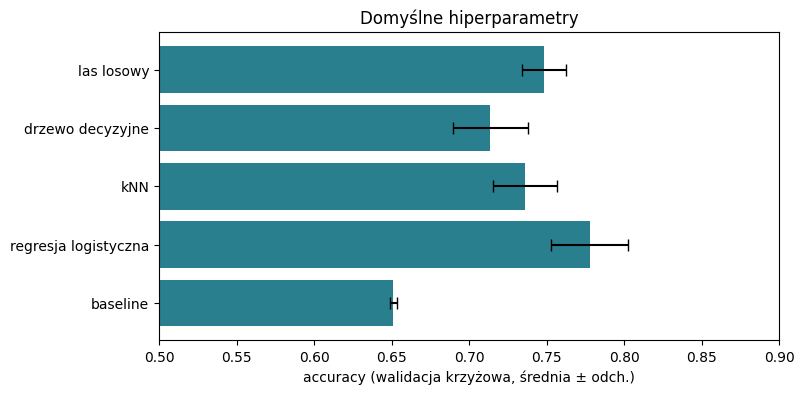

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(porownanie.index, porownanie["CV średnia"], xerr=porownanie["CV odch."], capsize=4, color="#2a7f8f")
ax.set_xlim(0.5, 0.9)
ax.set_xlabel("accuracy (walidacja krzyżowa, średnia ± odch.)")
ax.set_title("Domyślne hiperparametry")
plt.show()

In [ ]:
# TEST
assert list(porownanie.index) == ["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"]
assert abs(porownanie.loc["baseline", "CV średnia"] - 0.651) < 1e-2
assert abs(porownanie.loc["regresja logistyczna", "CV średnia"] - 0.778) < 1e-2
assert porownanie.loc["drzewo decyzyjne", "train"] > 0.99
print("5 OK")

5 OK


---
## 6. Krzywa walidacji dla kNN
Policz `validation_curve` dla `kneighborsclassifier__n_neighbors` w `ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]`. Wyniki zapisz w `tren`, `walid`; narysuj średnie (trening i walidacja) w funkcji k.

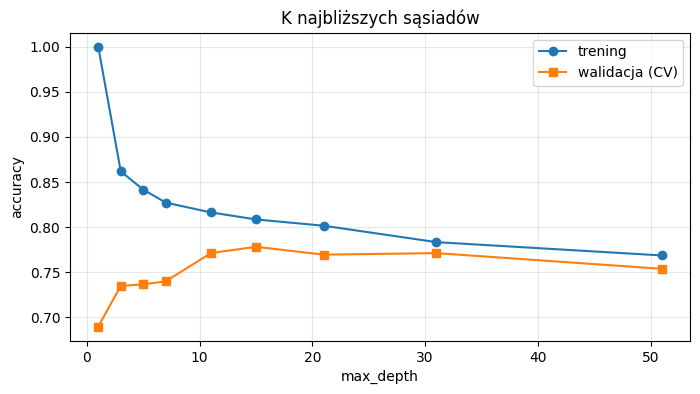

,1,3,5,7,11,15,21,31,51
trening,1.000,0.862,0.841,0.827,0.816,0.808,0.801,0.783,0.768
walidacja,0.689,0.734,0.736,0.740,0.771,0.778,0.769,0.771,0.753


In [ ]:
# Twoje rozwiązanie
glebokosci = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]
ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]
tren, walid = validation_curve(
    model_z(KNeighborsClassifier()), X_train, y_train,
    param_name="kneighborsclassifier__n_neighbors", param_range=ks, cv=cv)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ks, tren.mean(axis=1), "o-", label="trening")
ax.plot(ks, walid.mean(axis=1), "s-", label="walidacja (CV)")
ax.set_xlabel("max_depth")
ax.set_ylabel("accuracy")
ax.set_title("K najbliższych sąsiadów")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

pd.DataFrame({"trening": tren.mean(axis=1), "walidacja": walid.mean(axis=1)}, index=ks).round(3).T

In [ ]:
# TEST
assert tren.shape == (9, 5) and walid.shape == (9, 5)
assert tren.mean(axis=1)[0] == 1.0, "Dla k=1 wynik treningowy powinien wynosić 1.0"
print("6 OK")

6 OK


*Twoja odpowiedź:*
Dlaczego dla k = 1 wynik treningowy wynosi dokładnie 1.0?
- Dla k = 1 każda obserwacja treningowa jest swoim własnym najbliższym sąsiadem (odległość 0), więc model po prostu zapamiętuje etykiety i trafia w każdy przykład treningowy – stąd dokładnie 1,0.
Gdzie jest przeuczenie, a gdzie niedouczenie?
- Przeuczenie pojawia się przy małym k, a niedouczenie przy dużym k.

*(Komentarz do nauki dla mnie: Aby wyłapać charakterystyczne cechy kulturowe danego regionu, to nie powinno się przeprowadzać ankiety tylko u jednej osoby, bo wtedy wszystkie jej cechy zostaną uznane za cechy regionalne, ale też nie powinno się przeprowadzać ankiety w całym kraju, bo wtedy nie wyłapie się regionalnej popularności jakiejś cechy, bo zostanie to uśrednione przez odpowiedzi całego kraju.)*


---
## 7. Strojenie: `GridSearchCV`
Dla każdego z czterech klasyfikatorów uruchom `GridSearchCV(model_z(...), siatka, cv=cv)` na zbiorze treningowym. Siatki:
- regresja logistyczna: `C` ∈ {0.01, 0.1, 1, 10, 100},
- kNN: `n_neighbors` ∈ {1, 3, 5, 7, 11, 15, 21, 31},
- drzewo: `max_depth` ∈ {2, 3, 4, 5, 6, 8, None},
- las losowy: `max_depth` ∈ {3, 5, 8, None}, `n_estimators` ∈ {100, 300}.

Nauczone obiekty zapisz w słowniku `wyniki_gs` (klucze jak w punkcie 5, bez baseline'u) i wypisz najlepsze parametry oraz `best_score_` każdego modelu.

In [ ]:
# Twoje rozwiązanie
siatki = {
    "regresja logistyczna": (LogisticRegression(), {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
    "kNN": (KNeighborsClassifier(), {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]}),
    "drzewo decyzyjne": (DecisionTreeClassifier(random_state=42),
                         {"decisiontreeclassifier__max_depth": [2, 3, 4, 5, 6, 8, None]}),
    "las losowy": (RandomForestClassifier(random_state=42),
                   {"randomforestclassifier__max_depth": [3, 5, 8, None],
                    "randomforestclassifier__n_estimators": [100, 300]}),
}

wyniki_gs = {}
for nazwa, (klf, siatka) in siatki.items():
    gs = GridSearchCV(model_z(klf), siatka, cv=cv)
    gs.fit(X_train, y_train)
    wyniki_gs[nazwa] = gs
    print(f"{nazwa:22s} najlepszy parametr: {gs.best_params_} ; CV = {gs.best_score_:.3f}")

regresja logistyczna   najlepszy parametr: {'logisticregression__C': 1} ; CV = 0.778
kNN                    najlepszy parametr: {'kneighborsclassifier__n_neighbors': 15} ; CV = 0.778
drzewo decyzyjne       najlepszy parametr: {'decisiontreeclassifier__max_depth': 5} ; CV = 0.750
las losowy             najlepszy parametr: {'randomforestclassifier__max_depth': 3, 'randomforestclassifier__n_estimators': 300} ; CV = 0.762


In [ ]:
# TEST
assert set(wyniki_gs) == {"regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"}
assert all(hasattr(gs, "best_estimator_") for gs in wyniki_gs.values())
assert all(gs.best_score_ > 0.7 for gs in wyniki_gs.values())
print("7 OK")

7 OK


---
## 8. Wybór modelu i ocena końcowa
1. `najlepszy` – nazwa modelu z najwyższym `best_score_`; `model_koncowy` – jego `best_estimator_`.
2. `acc_test` – accuracy `model_koncowy` na zbiorze testowym (**jedyny raz, kiedy używasz `X_test`**).
3. Macierz pomyłek (`ConfusionMatrixDisplay`) i `classification_report`.

wybrany model: regresja logistyczna {'logisticregression__C': 1}
szacunek z CV:   0.778
wynik na teście: 0.724


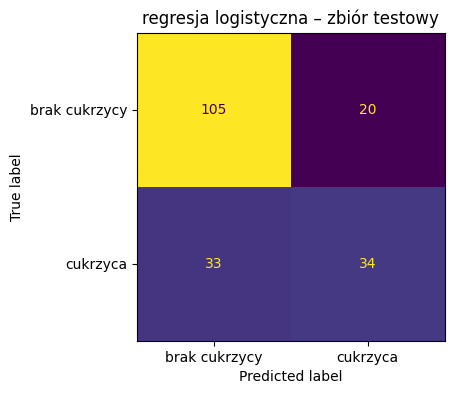

               precision    recall  f1-score   support

brak cukrzycy      0.761     0.840     0.798       125
     cukrzyca      0.630     0.507     0.562        67

     accuracy                          0.724       192
    macro avg      0.695     0.674     0.680       192
 weighted avg      0.715     0.724     0.716       192



In [ ]:
# Twoje rozwiązanie
najlepszy = max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_
acc_test = model_koncowy.score(X_test, y_test)
print("wybrany model:", najlepszy, wyniki_gs[najlepszy].best_params_)
print(f"szacunek z CV:   {wyniki_gs[najlepszy].best_score_:.3f}")
print(f"wynik na teście: {acc_test:.3f}")

y_pred = model_koncowy.predict(X_test)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["brak cukrzycy", "cukrzyca"]).plot(ax=ax, colorbar=False)
ax.set_title(f"{najlepszy} – zbiór testowy")
plt.show()
print(classification_report(y_test, y_pred, target_names=["brak cukrzycy", "cukrzyca"], digits=3))

In [ ]:
# TEST
assert najlepszy == max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
assert 0.65 < acc_test < 0.9
print("8 OK")

8 OK


*Twoja odpowiedź:*
1. Jak wynik testowy ma się do szacunku z walidacji krzyżowej? Czy różnica cię niepokoi? (Zbiór testowy ma 192 pacjentki – ile p.p. to jedna osoba?)
- Wynik testowy różni się o 0.054 (5 p.p.). Jedna osoba w zbiorze to ~0.0052 (0.5 p.p). W związku z tym różnica dot. 10 osób.
- Różnica jest niepokojąca zważywszy na proporcję ilości pacjentek, których obejmuje do liczby wszystkich pacjentek.
3. Jaki jest recall dla klasy „cukrzyca”? Co oznacza on dla pacjentek? Czy accuracy to dobra metryka do wyboru modelu w tym zastosowaniu?
- Recall dla klasy „cukrzyca” wynosi 0.507.
- Dla pacjentek oznacza to, że mają ok. 50% szansy na niewykrycie i tym samym niedopusczenie do leczenia.
- Accuracy to zła metryka w tym przypadku.
4. Modele w czołówce różnią się w CV o 1–2 p.p., a odchylenia wynoszą ok. 2–3 p.p. Czy można jednoznacznie wskazać „najlepszy” algorytm?
- W tym przypadku nie jest to łatwe, aby wskazać jednoznacznie "najlepszy" algorytm, tym bardziej, że zastosowana metryka to accuracy, a to nie jest właściwa metryka jak już wspomniałem w punkcie 3.

---
## 9. Dla chętnych
1. Powtórz punkty 7–8 z `scoring="recall"` w `GridSearchCV`. Czy zmienił się wybrany model? Co stało się z precision?
2. Dodaj do imputera `add_indicator=True` (flagi braków). Czy sam fakt braku pomiaru insuliny niesie informację?
3. Sprawdź, jak wyglądałyby wyniki, gdyby zostawić zera zamiast `NaN` (punkt 3 pominięty). Czy różnica jest duża? Dlaczego może być mała?